<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Preperation
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        1. Import important libraries and data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import LSTM, Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop, Adam
from keras_tuner.tuners import RandomSearch
from helper_functions import create_sequences_lstm, update_sequence
from sklearn.model_selection import TimeSeriesSplit

In [2]:
# Import the Data
utilization = pd.read_csv('utilization_final.csv')

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        2. Prepare the data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [3]:
# Convert the ingap variable to an int
utilization['in_gap'] = utilization['in_gap'].astype(int)

# Convert the 'timestamp' column to the pandas datetime format
utilization['timestamp'] = pd.to_datetime(utilization['timestamp'])

# Cut the data at the point where covid started
cutoff_time = pd.to_datetime('2020-03-18 23:59:59')
duplicate_rows = utilization[utilization['timestamp'] < cutoff_time].index
utilization.drop(duplicate_rows,inplace=True)

In [4]:
# Drop the columns we don't need for the model from here
utilization.drop(['utilization_absolute', 
       'precipitation', 
        'hour','winter','autumn','summer','friday','day_of_week'],axis=1,inplace=True)

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        3. Scale the Data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [5]:
# Scale the features to (0, 1)
scaler = MinMaxScaler()
scaled_columns = ['utilization_perc', 'temperature', 'site_01',
       'hour_sin', 'hour_cos',  'weekday_sin', 'weekday_cos',
       'month_sin', 'month_cos', 'in_gap','stay_at_home','weekday','month','weekend']
utilization[scaled_columns] = scaler.fit_transform(utilization[scaled_columns])

# Convert to a DataFrame
utilization = pd.DataFrame(utilization, columns=utilization.columns)

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        4. Prepare the Test-Train-Split
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [6]:
# Split the data 
train_data = utilization[utilization['timestamp'] < '2021-08-16'].copy()
test_data = utilization[(utilization['timestamp'] >= '2021-08-16') & (utilization['timestamp'] < '2021-09-13 19:00')].copy()

# Create a 'date' column for grouping
train_data["date"] = train_data["timestamp"].dt.date
test_data["date"] = test_data["timestamp"].dt.date

# Sort by date, then by site, and then by timestamp
train_data = train_data.sort_values(by=["date", "site_01", "timestamp"]).reset_index(drop=True)
test_data = test_data.sort_values(by=["date", "site_01", "timestamp"]).reset_index(drop=True)

# Drop the timestamp column
train_data.drop(['timestamp','date'],axis=1,inplace = True)
test_data.drop(['date'],axis=1,inplace = True)

In [7]:
# Define sequence length 
sequence_length = 24
target_column = "utilization_perc"
X, y = create_sequences_lstm(train_data, sequence_length, target_column)

# Check shapes
print("Input shape (X):", X.shape)  # (samples, sequence_length, features)
print("Output shape (y):", y.shape)  # (samples,)

Input shape (X): (24586, 24, 15)
Output shape (y): (24586,)


In [8]:
# Split into training and testing sets
split = int(0.8 * len(X))
X_train, X_val = X[:split], X[split:]
y_train, y_val = y[:split], y[split:]

<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Model
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        1. Cross Validation
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [11]:
tscv = TimeSeriesSplit(n_splits=5)  # You can change n_splits based on your requirement
all_val_losses = []

# Loop over each fold
for train_idx, val_idx in tscv.split(X):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    # Build the model for each fold
    model = Sequential([
        Input(shape=(X_train.shape[1], X_train.shape[2])),  # sequence_length, features
        LSTM(32, activation='tanh', return_sequences=False),
        Dense(16, activation='relu'),
        Dense(1),
    ])

    # Compile the model
    optimizer = RMSprop(learning_rate=0.001)
    model.compile(optimizer=optimizer, loss='mae')
    model.summary()

    # Define early stopping to avoid overfitting
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

    # Train the model
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=16,
        callbacks=[early_stopping],
        verbose=0
    )

    # Evaluate the model on validation set
    val_loss = model.evaluate(X_val, y_val, verbose=0)
    print(f"Fold Validation Loss: {val_loss}")
    
    # Store validation loss for each fold
    all_val_losses.append(val_loss)

# Calculate and print the average validation loss across all folds
avg_val_loss = np.mean(all_val_losses)
print(f"Average Validation Loss across all folds: {avg_val_loss}")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,689 (26.13 KB)

 Trainable params: 6,689 (26.13 KB)

 Non-trainable params: 0 (0.00 B)

Fold Validation Loss: 0.010283230803906918


... (20 outputs left out)

 Total params: 6,689 (26.13 KB)

 Trainable params: 6,689 (26.13 KB)

 Non-trainable params: 0 (0.00 B)

Fold Validation Loss: 0.01778302900493145
Average Validation Loss across all folds: 0.012297971826046705


In [12]:
model = Sequential([
    Input(shape=(sequence_length, X.shape[2])),  
    LSTM(32, activation='tanh', return_sequences=False),
    Dense(16, activation='relu'),
    Dense(1)
])

# Compile the model
optimizer = RMSprop(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mae')
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_5 (LSTM)                   │ (None, 32)             │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,689 (26.13 KB)

 Trainable params: 6,689 (26.13 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,  
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0373 - val_loss: 0.0333
Epoch 2/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0149 - val_loss: 0.0340
Epoch 3/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0127 - val_loss: 0.0241
Epoch 4/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0117 - val_loss: 0.0229
Epoch 5/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0111 - val_loss: 0.0220
Epoch 6/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0104 - val_loss: 0.0209
Epoch 7/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0101 - val_loss: 0.0197
Epoch 8/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0099 - val_loss: 0.0196
Epoch 9/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0097 - val_loss: 0.0202
Epoch 10/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0095 - val_loss: 0.0192
Epoch 11/100
1281/1281 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0096 - val_loss: 0.0198
Epoch 12/100
1281/1

In [14]:
best_mae_index = history.history['val_loss'].index(min(history.history['val_loss']))
best_mae = history.history['val_loss'][best_mae_index]

print(f"Best Validation MAE: {best_mae:.5f} at Epoch {best_mae_index + 1}")

Best Validation MAE: 0.01806 at Epoch 16


<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        2. Test the model
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [15]:
# Split the test data to get results for each site
test_data1 = test_data[test_data['site_01']==1]
test_data2 = test_data[test_data['site_01']==0]

# Create sequences from the data
X_test_1, y_test_1 = create_sequences_lstm(test_data1.drop(['timestamp'],axis=1), sequence_length, target_column)
X_test_2, y_test_2 = create_sequences_lstm(test_data2.drop(['timestamp'],axis=1), sequence_length, target_column)

In [16]:
# Create empty lists to store the predictions
predictions_1 = []
predictions_2 = []

# Get the predictions for each site
input_sequence = X_test_1[0]  
for i in range(667):  
    input_sequence = X_test_1[i]
    pred = model.predict(input_sequence.reshape(1, 24, 15),verbose=0)
    predictions_1.extend(pred[0]) 
    i += 1 
    
input_sequence = X_test_2[0]  
for i in range(667):  
    input_sequence = X_test_2[i]
    pred = model.predict(input_sequence.reshape(1, 24, 15),verbose=0)
    predictions_2.extend(pred[0])  
    i += 1
    
mae_1 = mean_absolute_error(y_test_1, predictions_1)
mae_2 = mean_absolute_error(y_test_2, predictions_2)
print(f"Mean Absolute Error (MAE) for site 01: {mae_1}")
print(f"Mean Absolute Error (MAE) for site 02: {mae_2}")

Mean Absolute Error (MAE) for site 01: 0.031958472034223015
Mean Absolute Error (MAE) for site 02: 0.020703220965390113


<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Visualizations
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [17]:
test_data1 = test_data1[24:].copy()
test_data2= test_data2[24:].copy()

test_data1['predictions_site_01'] = predictions_1
test_data2['predictions_site_01'] = predictions_2

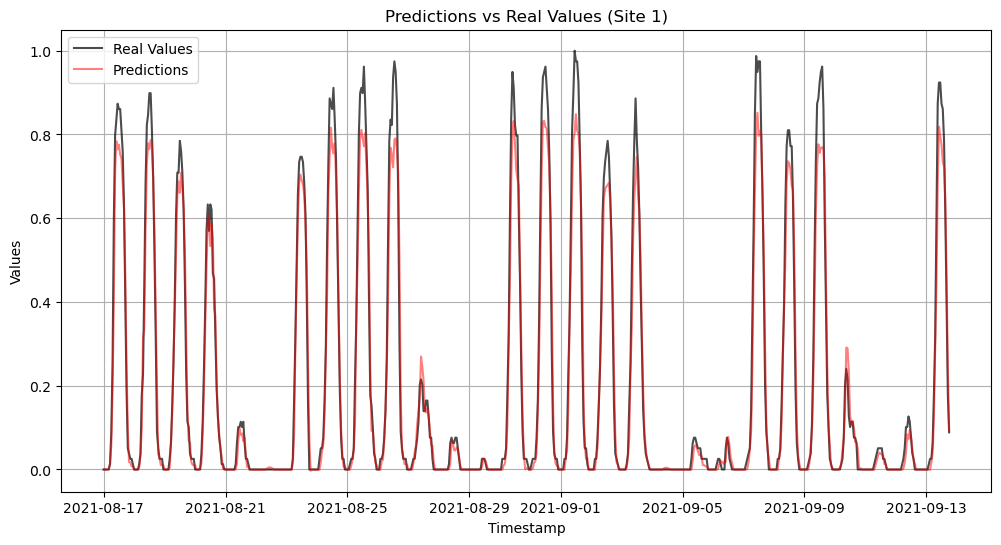

In [18]:
# Calculate the residuals for the first site
test_data1['residuals'] = test_data1['utilization_perc'] - test_data1['predictions_site_01']
# Add a column for weekdays
test_data1['weekday'] = test_data1['timestamp'].dt.day_name()  

# Plot the Predictions
plt.figure(figsize=(12, 6))

plt.plot(test_data1['timestamp'], test_data1['utilization_perc'], label='Real Values', color='black', alpha=0.7)
plt.plot(test_data1['timestamp'], test_data1['predictions_site_01'], label='Predictions', color='red', alpha=0.5)

plt.title('Predictions vs Real Values (Site 1)')
plt.xlabel('Timestamp')
plt.ylabel('Values')
plt.legend()
plt.grid()
plt.show()

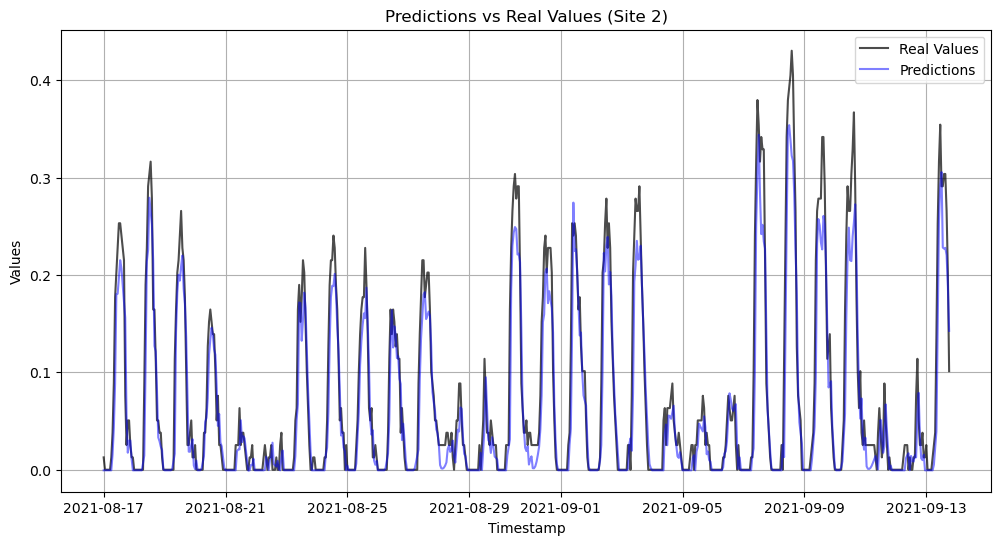

In [19]:
# Calculate the residuals for the second site
test_data2['residuals'] = test_data2['utilization_perc'] - test_data2['predictions_site_01']

# Add a column for weekdays
test_data2['weekday'] = test_data2['timestamp'].dt.day_name()  

# Plot the Predictions
plt.figure(figsize=(12, 6))

plt.plot(test_data2['timestamp'], test_data2['utilization_perc'], label='Real Values', color='black', alpha=0.7)
plt.plot(test_data2['timestamp'], test_data2['predictions_site_01'], label='Predictions', color='blue', alpha=0.5)

plt.title('Predictions vs Real Values (Site 2)')
plt.xlabel('Timestamp')
plt.ylabel('Values')
plt.legend()
plt.grid()
plt.show()

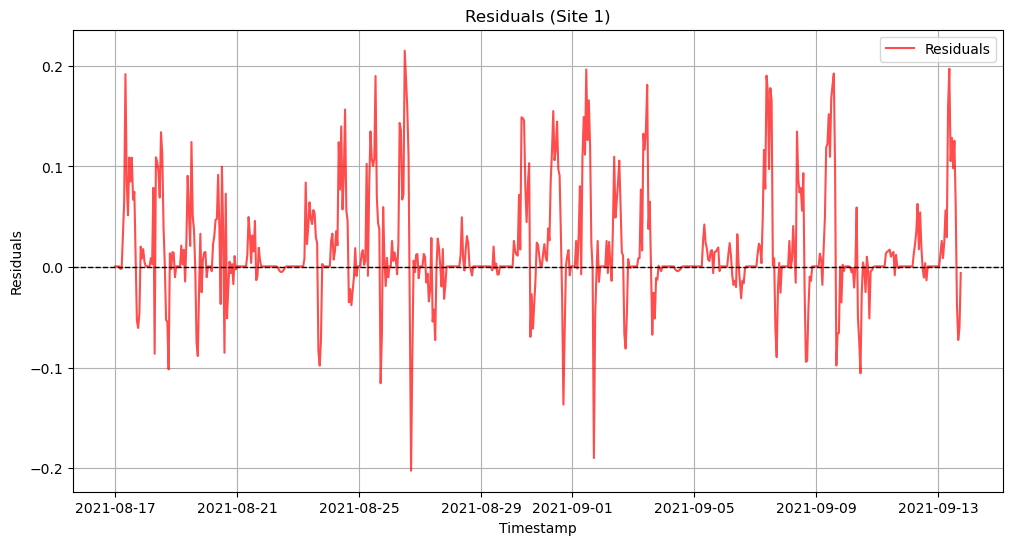

In [20]:
# Plot the residuals for the first site
plt.figure(figsize=(12, 6))

plt.plot(test_data1['timestamp'], test_data1['residuals'], label='Residuals', color='red', alpha=0.7)
plt.axhline(0, color='black', linestyle='--', linewidth=1)  

plt.title('Residuals (Site 1)')
plt.xlabel('Timestamp')
plt.ylabel('Residuals')
plt.legend()
plt.grid()
plt.show()


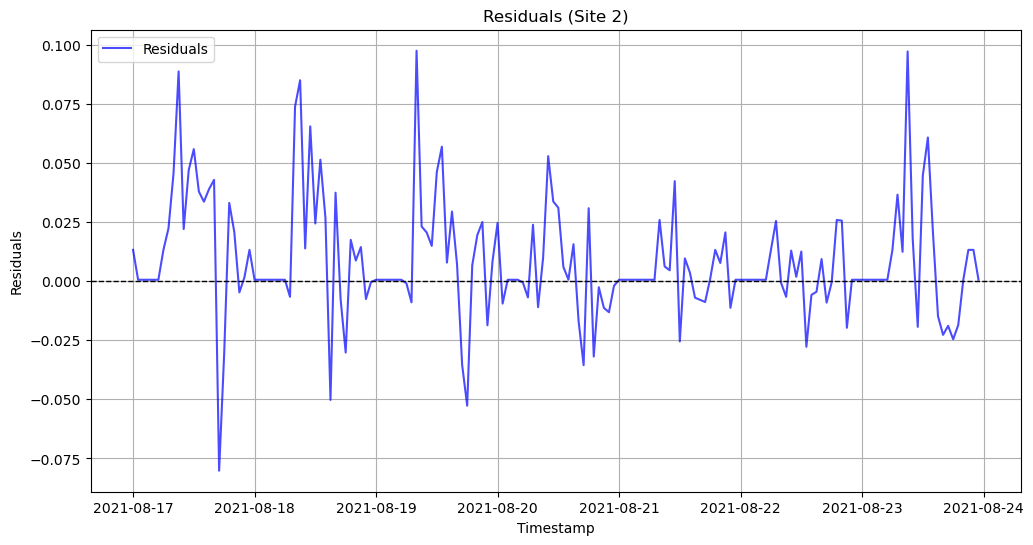

In [21]:
# Plot the residuals for the second site
plt.figure(figsize=(12, 6))

plt.plot(test_data2['timestamp'][:168], test_data2['residuals'][:168], label='Residuals', color='blue', alpha=0.7)
plt.axhline(0, color='black', linestyle='--', linewidth=1)  

plt.title('Residuals (Site 2)')
plt.xlabel('Timestamp')
plt.ylabel('Residuals')
plt.legend()
plt.grid()
plt.show()

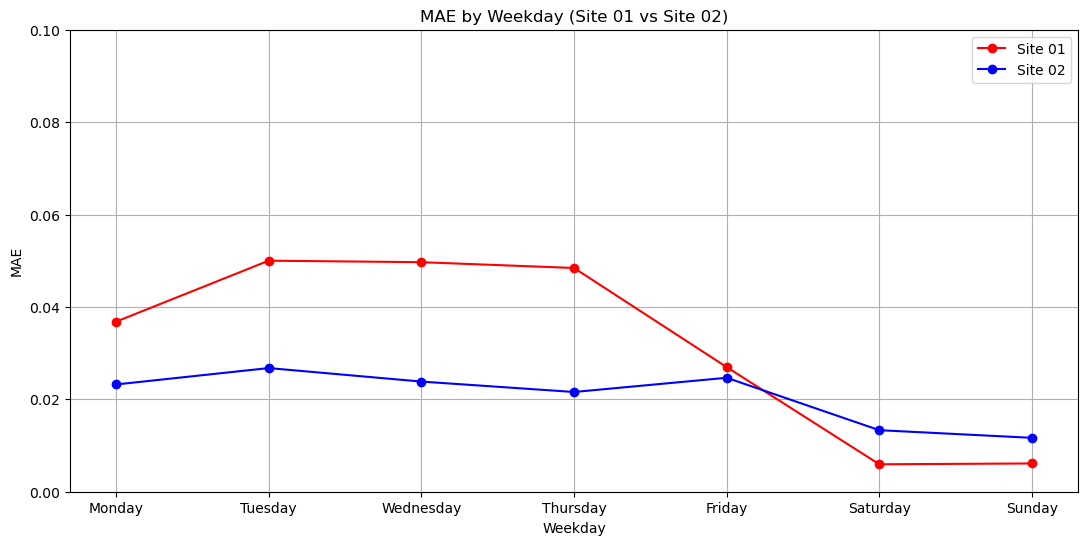

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

# Assuming test_data1 and test_data2 are your datasets and have the 'residuals' and 'weekday' columns

# Process the first dataset (Site 01)
test_data1['residuals'] = test_data1['residuals'].abs()
weekday_avg1 = test_data1.groupby('weekday').mean(numeric_only=True)
weekday_avg1 = weekday_avg1.reset_index()

# Sort weekdays for Site 01
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_avg1['weekday'] = pd.Categorical(weekday_avg1['weekday'], categories=weekday_order, ordered=True)
weekday_avg1 = weekday_avg1.sort_values('weekday')

# Process the second dataset (Site 02)
test_data2['residuals'] = test_data2['residuals'].abs()
weekday_avg2 = test_data2.groupby('weekday').mean(numeric_only=True)
weekday_avg2 = weekday_avg2.reset_index()

# Sort weekdays for Site 02
weekday_avg2['weekday'] = pd.Categorical(weekday_avg2['weekday'], categories=weekday_order, ordered=True)
weekday_avg2 = weekday_avg2.sort_values('weekday')

# Plotting both datasets in one plot
plt.figure(figsize=(13, 6))

# Plot for Site 01 (red)
plt.plot(weekday_avg1['weekday'], weekday_avg1['residuals'], marker='o', label='Site 01', color='red')

# Plot for Site 02 (blue)
plt.plot(weekday_avg2['weekday'], weekday_avg2['residuals'], marker='o', label='Site 02', color='blue')

# Labeling and Title
plt.xlabel('Weekday')
plt.ylabel('MAE')
plt.ylim(0, 0.1)
plt.title('MAE by Weekday (Site 01 vs Site 02)')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()


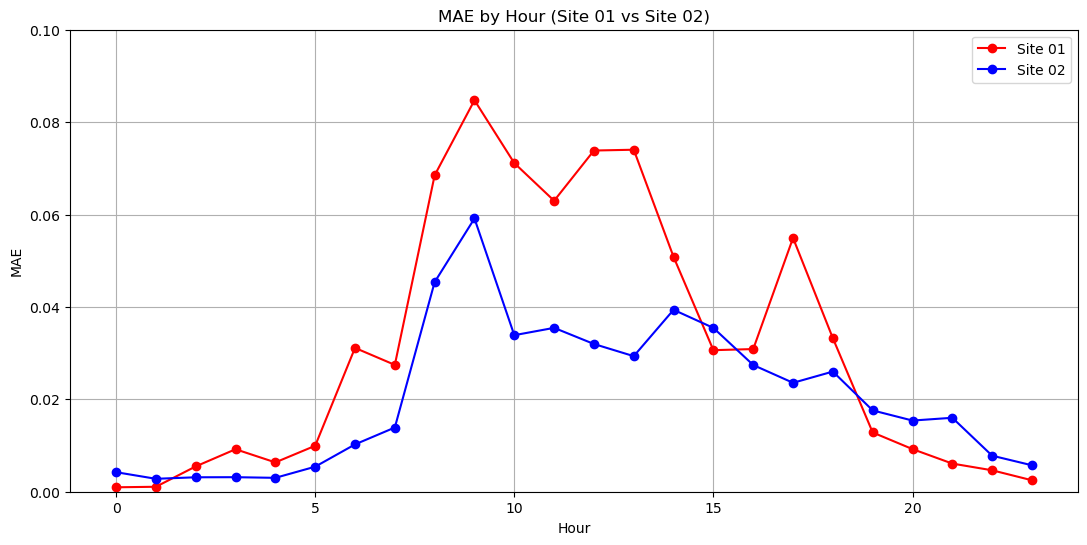

In [28]:
# Process the first dataset (Site 01)
test_data1['hour'] = test_data1['timestamp'].dt.hour
hourly_avg1 = test_data1.groupby('hour').mean(numeric_only=True)
hourly_avg1 = hourly_avg1.reset_index()

# Process the second dataset (Site 02)
test_data2['hour'] = test_data2['timestamp'].dt.hour
hourly_avg2 = test_data2.groupby('hour').mean(numeric_only=True)
hourly_avg2 = hourly_avg2.reset_index()

# Plotting both datasets in one plot
plt.figure(figsize=(13, 6))

# Plot for Site 01 (red)
plt.plot(hourly_avg1['hour'], hourly_avg1['residuals'], marker='o', label='Site 01', color='red')

# Plot for Site 02 (blue)
plt.plot(hourly_avg2['hour'], hourly_avg2['residuals'], marker='o', label='Site 02', color='blue')

# Labeling and Title
plt.xlabel('Hour')
plt.ylabel('MAE')
plt.ylim(0, 0.1)
plt.title('MAE by Hour (Site 01 vs Site 02)')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()